## Run SUMMA and MizuRoute ESP ##

Run the SUMMA and ESP models, with the model runs managed by Snakemake


### Write snakemake file ###

This block of code writes the snakemake file

In [4]:
import os, sys
from pathlib import Path
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pprint import pprint
import yaml

In [39]:
config_file = "/Users/dcasson/GitHub/snow_dist/snakemake/config/chena_above_two_rivers.yaml"
config_file_path = Path(config_file).resolve()

# Read config yaml as dict
with open(config_file_path, 'r') as stream:
    config_dict = yaml.safe_load(stream)

sys.path.append('../scripts/')
import ss_utils
import model_run_utils
import plotting
from ensemble_analysis import *
# Promote config keys
config = ss_utils.promote_keys(config_dict)
pprint(config)

# Add magic for reloading modules
%load_ext autoreload
%autoreload 2

{'attributes_nc': 'attributes.nc',
 'case_name': 'Chena',
 'esp_months': [3, 4, 5, 6, 7, 8],
 'esp_start_year': 2008,
 'esp_stop_year': 2018,
 'file_manager': '/Users/dcasson/Data/yukon_esp/summa/settings/fileManager.txt',
 'forecast_length_days': 30,
 'gru_chunk_size': 3,
 'mizuroute_cold_state': 'mizuroute_cold_state.nc',
 'mizuroute_control_file': 'mizuroute.control',
 'mizuroute_exe': '/Users/dcasson/GitHub/mizuRoute/route/bin/mizuroute.exe',
 'mizuroute_output_path': '/Users/dcasson/Data/yukon_esp/mizuroute_output/',
 'mizuroute_restart_path': '/Users/dcasson/Data/yukon_esp/mizuroute_output/restart_files/',
 'mizuroute_settings_path': '/Users/dcasson/Data/yukon_esp/mizuroute/',
 'model_end_time': '2003-09-30 23:00',
 'model_run_path': '/Users/dcasson/Data/yukon_esp/output/',
 'model_start_time': '2001-10-01 00:00',
 'restart_file_filter': 'restart',
 'run_suffix': 'base',
 'summa_cold_state': 'coldState.nc',
 'summa_exe': '/Users/dcasson/GitHub/summa/bin/summa.exe',
 'summa_output

### Get forecast start dates

In [40]:
summa_restart_path = config['summa_restart_path']
filter_str = config['restart_file_filter']
months = config['esp_months']

files_by_date = ss_utils.get_files_by_date(summa_restart_path, filter_str, months)
date_list = list(files_by_date.keys())
print(f"Date List: {date_list}")


Date List: ['2003060100', '2002060100', '2002080100', '2003080100', '2003040100', '2002040100', '2002070100', '2003070100', '2002050100', '2003050100', '2002030100', '2003030100']


## Build streamflow climatology

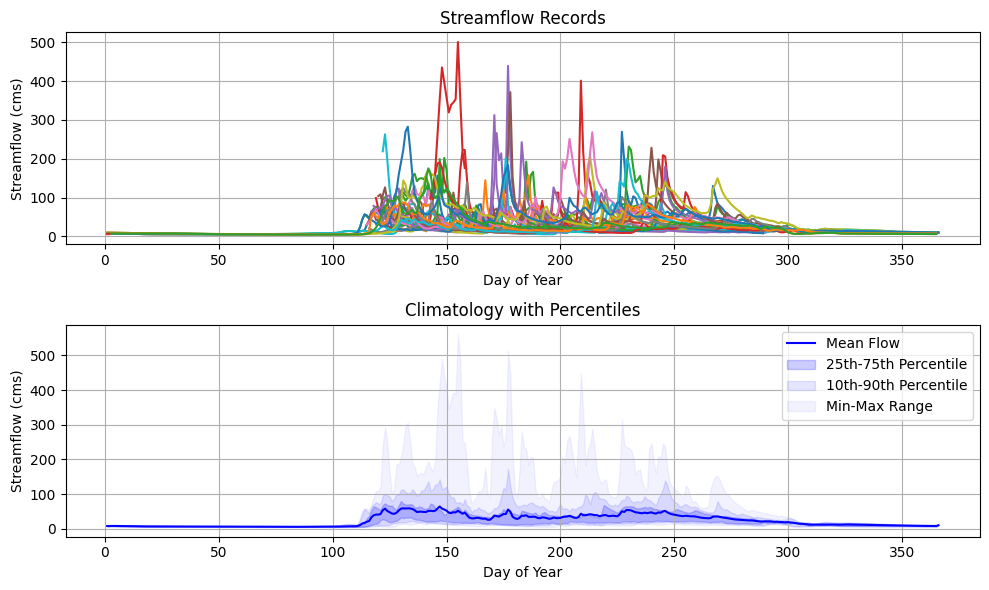

In [41]:
streamflow_obs = pd.read_csv("/Users/dcasson/Data/yukon_esp/observations/Chena_Near_Two_Rivers_streamflow_processed.csv")
climatology_df = plotting.calculate_annual_climatology(streamflow_obs)
climatology_df.to_csv("/Users/dcasson/Data/yukon_esp/observations/Chena_Near_Two_Rivers_streamflow_climatology.csv")
climatology_ds = xr.Dataset.from_dataframe(climatology_df)

plotting.plot_climatology(climatology_df)

In [42]:


ens_dir = Path('/Users/dcasson/Data/yukon_esp/mizuroute_output/Chena/2002060100/')
variable = 'IRFroutedRunoff'
reachID = '81014576'
# Read all files matching a string in a directory
ens_files = list(ens_dir.glob('*.nc'))
ens_files.sort()

ens_ds = read_ensemble_files(ens_files, variable, reachID)

obs_da = read_obs_data_matching_ens_dates(ens_ds, streamflow_obs)

obs_ens = match_ensemble_day_of_year(ens_ds, climatology_df,start_year=2008, end_year=2018)

CRPS, CRPSS = continuous_rank_prob_score(obs_da, statistics_input, ens_ds, 10)

print("CRPS mean:", np.nanmean(CRPS))
print("CRPSS mean:", np.nanmean(CRPSS))

CRPS mean: 33.208908818713205
CRPSS mean: -3.011029611279537
